In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importamos las funciones de tu ETL
from etl.extract import generar_datos_crudos
from etl.transform import calcular_kpis_calidad, aplicar_gobierno_y_calidad

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Librerías y módulos de ETL cargados correctamente.")

✅ Librerías y módulos de ETL cargados correctamente.


In [8]:
# 1. Generamos los datos crudos (El Mockup con errores intencionales)
df_crudo = generar_datos_crudos(15000)

# 2. Calculamos la calidad ANTES de la transformación
tcr_antes, ted_antes, tdr_antes = calcular_kpis_calidad(df_crudo)

# 3. Aplicamos el Gobierno de Datos (Transformación)
df_limpio, df_rechazos = aplicar_gobierno_y_calidad(df_crudo)

# 4. Calculamos la calidad DESPUÉS de la transformación
tcr_despues, ted_despues, tdr_despues = calcular_kpis_calidad(df_limpio)

print("✅ Datos procesados. Listos para graficar.")

📥 [EXTRACT] Generando datos crudos (V0 - Inmutable)...

🛡️ [TRANSFORM] Iniciando Validador de Calidad y Gobernanza...

📊 REPORTE DE HALLAZGOS DE CALIDAD (Auditoría):
------------------------------------------------------------
Registros procesados: 15000
  ➤ KPI 1 (TCR - Completitud): Subió de 92.3% a 100.0%
  ➤ KPI 2 (TED - Estandarización): Subió de 62.8% a 100.0%
  ➤ KPI 3 (TDR - En Rango): Subió de 96.1% a 100.0%
------------------------------------------------------------
📝 CONCLUSIÓN DEL DATA STEWARD:
De 15000 registros, se corrigieron automáticamente los errores tipográficos.
Sin embargo, 1018 registros fueron DESCARTADOS por no tener variable objetivo
o por tener ventas irreales. El dataset final tiene 13982 registros 100% fiables.
------------------------------------------------------------
✅ Datos procesados. Listos para graficar.


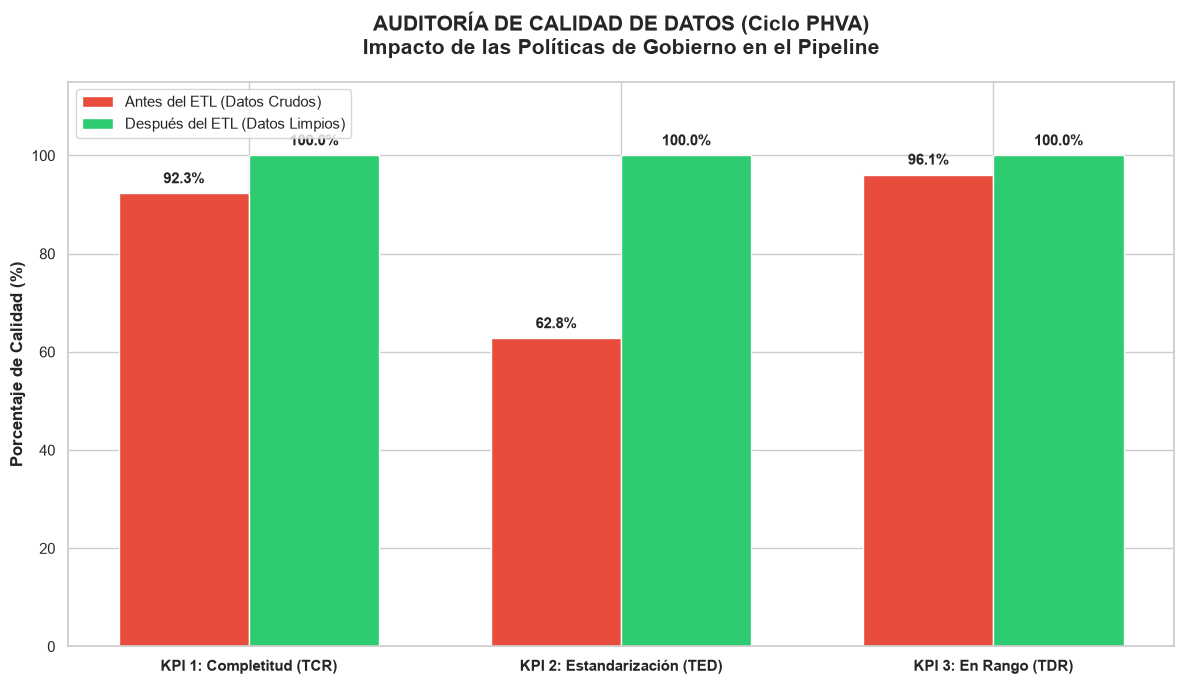

In [9]:
# Preparamos los datos para el gráfico
kpis = ['KPI 1: Completitud (TCR)', 'KPI 2: Estandarización (TED)', 'KPI 3: En Rango (TDR)']
valores_antes = [tcr_antes, ted_antes, tdr_antes]
valores_despues = [tcr_despues, ted_despues, tdr_despues]

x = range(len(kpis))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

# Dibujamos las barras
barras_antes = ax.bar([i - width/2 for i in x], valores_antes, width, label='Antes del ETL (Datos Crudos)', color='#e74c3c')
barras_despues = ax.bar([i + width/2 for i in x], valores_despues, width, label='Después del ETL (Datos Limpios)', color='#2ecc71')

# Configuramos el diseño
ax.set_ylabel('Porcentaje de Calidad (%)', fontsize=12, fontweight='bold')
ax.set_title('AUDITORÍA DE CALIDAD DE DATOS (Ciclo PHVA)\nImpacto de las Políticas de Gobierno en el Pipeline', fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(kpis, fontsize=11, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(loc='upper left', fontsize=11)

# Añadimos las etiquetas de porcentaje sobre las barras
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 5),  # 5 puntos de separación vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

autolabel(barras_antes)
autolabel(barras_despues)

plt.tight_layout()
plt.show()

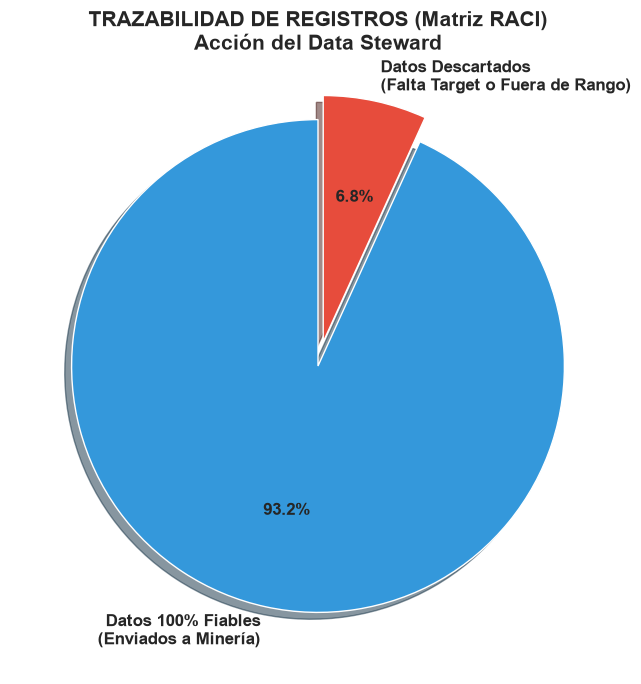

📝 RESUMEN DE AUDITORÍA:
Total de registros procesados: 15000
Registros aptos para Machine Learning: 13982
Registros enviados a cuarentena (staging_rechazos): 1018


In [10]:
# Datos para el gráfico de pastel
etiquetas = ['Datos 100% Fiables\n(Enviados a Minería)', 'Datos Descartados\n(Falta Target o Fuera de Rango)']
valores = [len(df_limpio), len(df_rechazos)]
colores = ['#3498db', '#e74c3c']
explode = (0, 0.1)  # Resaltar los rechazados

plt.figure(figsize=(8, 8))
plt.pie(valores, explode=explode, labels=etiquetas, colors=colores, autopct='%1.1f%%', 
        shadow=True, startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
plt.title('TRAZABILIDAD DE REGISTROS (Matriz RACI)\nAcción del Data Steward', fontsize=15, fontweight='bold')
plt.show()

print(f"📝 RESUMEN DE AUDITORÍA:")
print(f"Total de registros procesados: {len(df_crudo)}")
print(f"Registros aptos para Machine Learning: {len(df_limpio)}")
print(f"Registros enviados a cuarentena (staging_rechazos): {len(df_rechazos)}")

In [11]:
# Mostrar los primeros 10 registros que fueron rechazados por el Data Steward
print("🚫 MUESTRA DE DATOS RECHAZADOS (Cuarentena):")
display(df_rechazos[['id_producto_tienda_semana', 'ventas_unidades', 'quiebre_stock']].head(10))

🚫 MUESTRA DE DATOS RECHAZADOS (Cuarentena):


,id_producto_tienda_semana,ventas_unidades,quiebre_stock
51,REG-00052,104,NaN
72,REG-00073,118,NaN
76,REG-00077,123,NaN
77,REG-00078,108,NaN
90,REG-00091,300,1.0
94,REG-00095,500,0.0
100,REG-00101,300,1.0
116,REG-00117,-10,1.0
121,REG-00122,-10,1.0
146,REG-00147,500,0.0
